<a href="https://colab.research.google.com/github/farahmandzohreh9-netizen/Zora/blob/main/ADTA_5230_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ZF10_ADTA 5230 Final Project_ Spring 2026_8 Week 2



In [ ]:
# version https://git-lfs.github.com/spec/v1

In [9]:
import pandas as pd

df_turnover = pd.read_excel('/content/sample_data/Workforce_Turnover.xlsx')
display(df_turnover.head())

,DISTRICT,DISTNAME,TEA Description,DPFEIERP,DPSAINHP,DPSAMIFC,DPSAMIFP,DPSATOFC,DPSBTOFC,DPSBTOPC,...,DPSTWHFC,DPSTWHFP,DPSUTOFC,DPSUTOFP,DPSUTOSA,DPSXCOFC,DPSXTOFC,DPSXTOFP,TEA Description2,TEA Description3
0,'001902,CAYUGA ISD,Rural,57,71.3,12.8,12.5,102,0,1,...,46.5,96,6.4,6.2,57090,2.1,25.6,25.1,Rural,NaN
1,'001903,ELKHART ISD,Non-metropolitan Stable,61.5,68.8,25,13.2,189,0,0,...,93.5,89.5,9.9,5.2,60509,0,36.5,19.3,Non-metropolitan Stable,NaN
2,'001904,FRANKSTON ISD,Rural,54.4,61.5,16.7,11.8,141.7,0,0,...,64,94.1,2.7,1.9,59435,0,40.7,28.7,Rural,NaN
3,'001906,NECHES ISD,Rural,54.9,58.8,11.7,18.8,62.2,0,0,...,27.1,96.6,2,3.2,66243,0,14.6,23.4,Rural,NaN
4,'001907,PALESTINE ISD,Independent Town,57.4,70.3,193.9,34.5,561.6,0,0,...,182.4,72.6,48.2,8.6,66404,0,114.1,20.3,Independent Town,NaN


In [10]:
df_turnover.isnull()

,DISTRICT,DISTNAME,TEA Description,DPFEIERP,DPSAINHP,DPSAMIFC,DPSAMIFP,DPSATOFC,DPSBTOFC,DPSBTOPC,...,DPSTWHFC,DPSTWHFP,DPSUTOFC,DPSUTOFP,DPSUTOSA,DPSXCOFC,DPSXTOFC,DPSXTOFP,TEA Description2,TEA Description3
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1204,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1205,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1206,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1207,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [11]:
missing_values_count = df_turnover.isnull().sum()
display(missing_values_count)

,0
DISTRICT,0
DISTNAME,0
TEA Description,0
DPFEIERP,0
DPSAINHP,0
...,...
DPSXCOFC,0
DPSXTOFC,0
DPSXTOFP,0
TEA Description2,0


Missing: 102 rows × 1 columns

In [12]:
(df_turnover.isnull().mean()) * 100

,0
DISTRICT,0.0
DISTNAME,0.0
TEA Description,0.0
DPFEIERP,0.0
DPSAINHP,0.0
...,...
DPSXCOFC,0.0
DPSXTOFC,0.0
DPSXTOFP,0.0
TEA Description2,0.0


<Axes: >

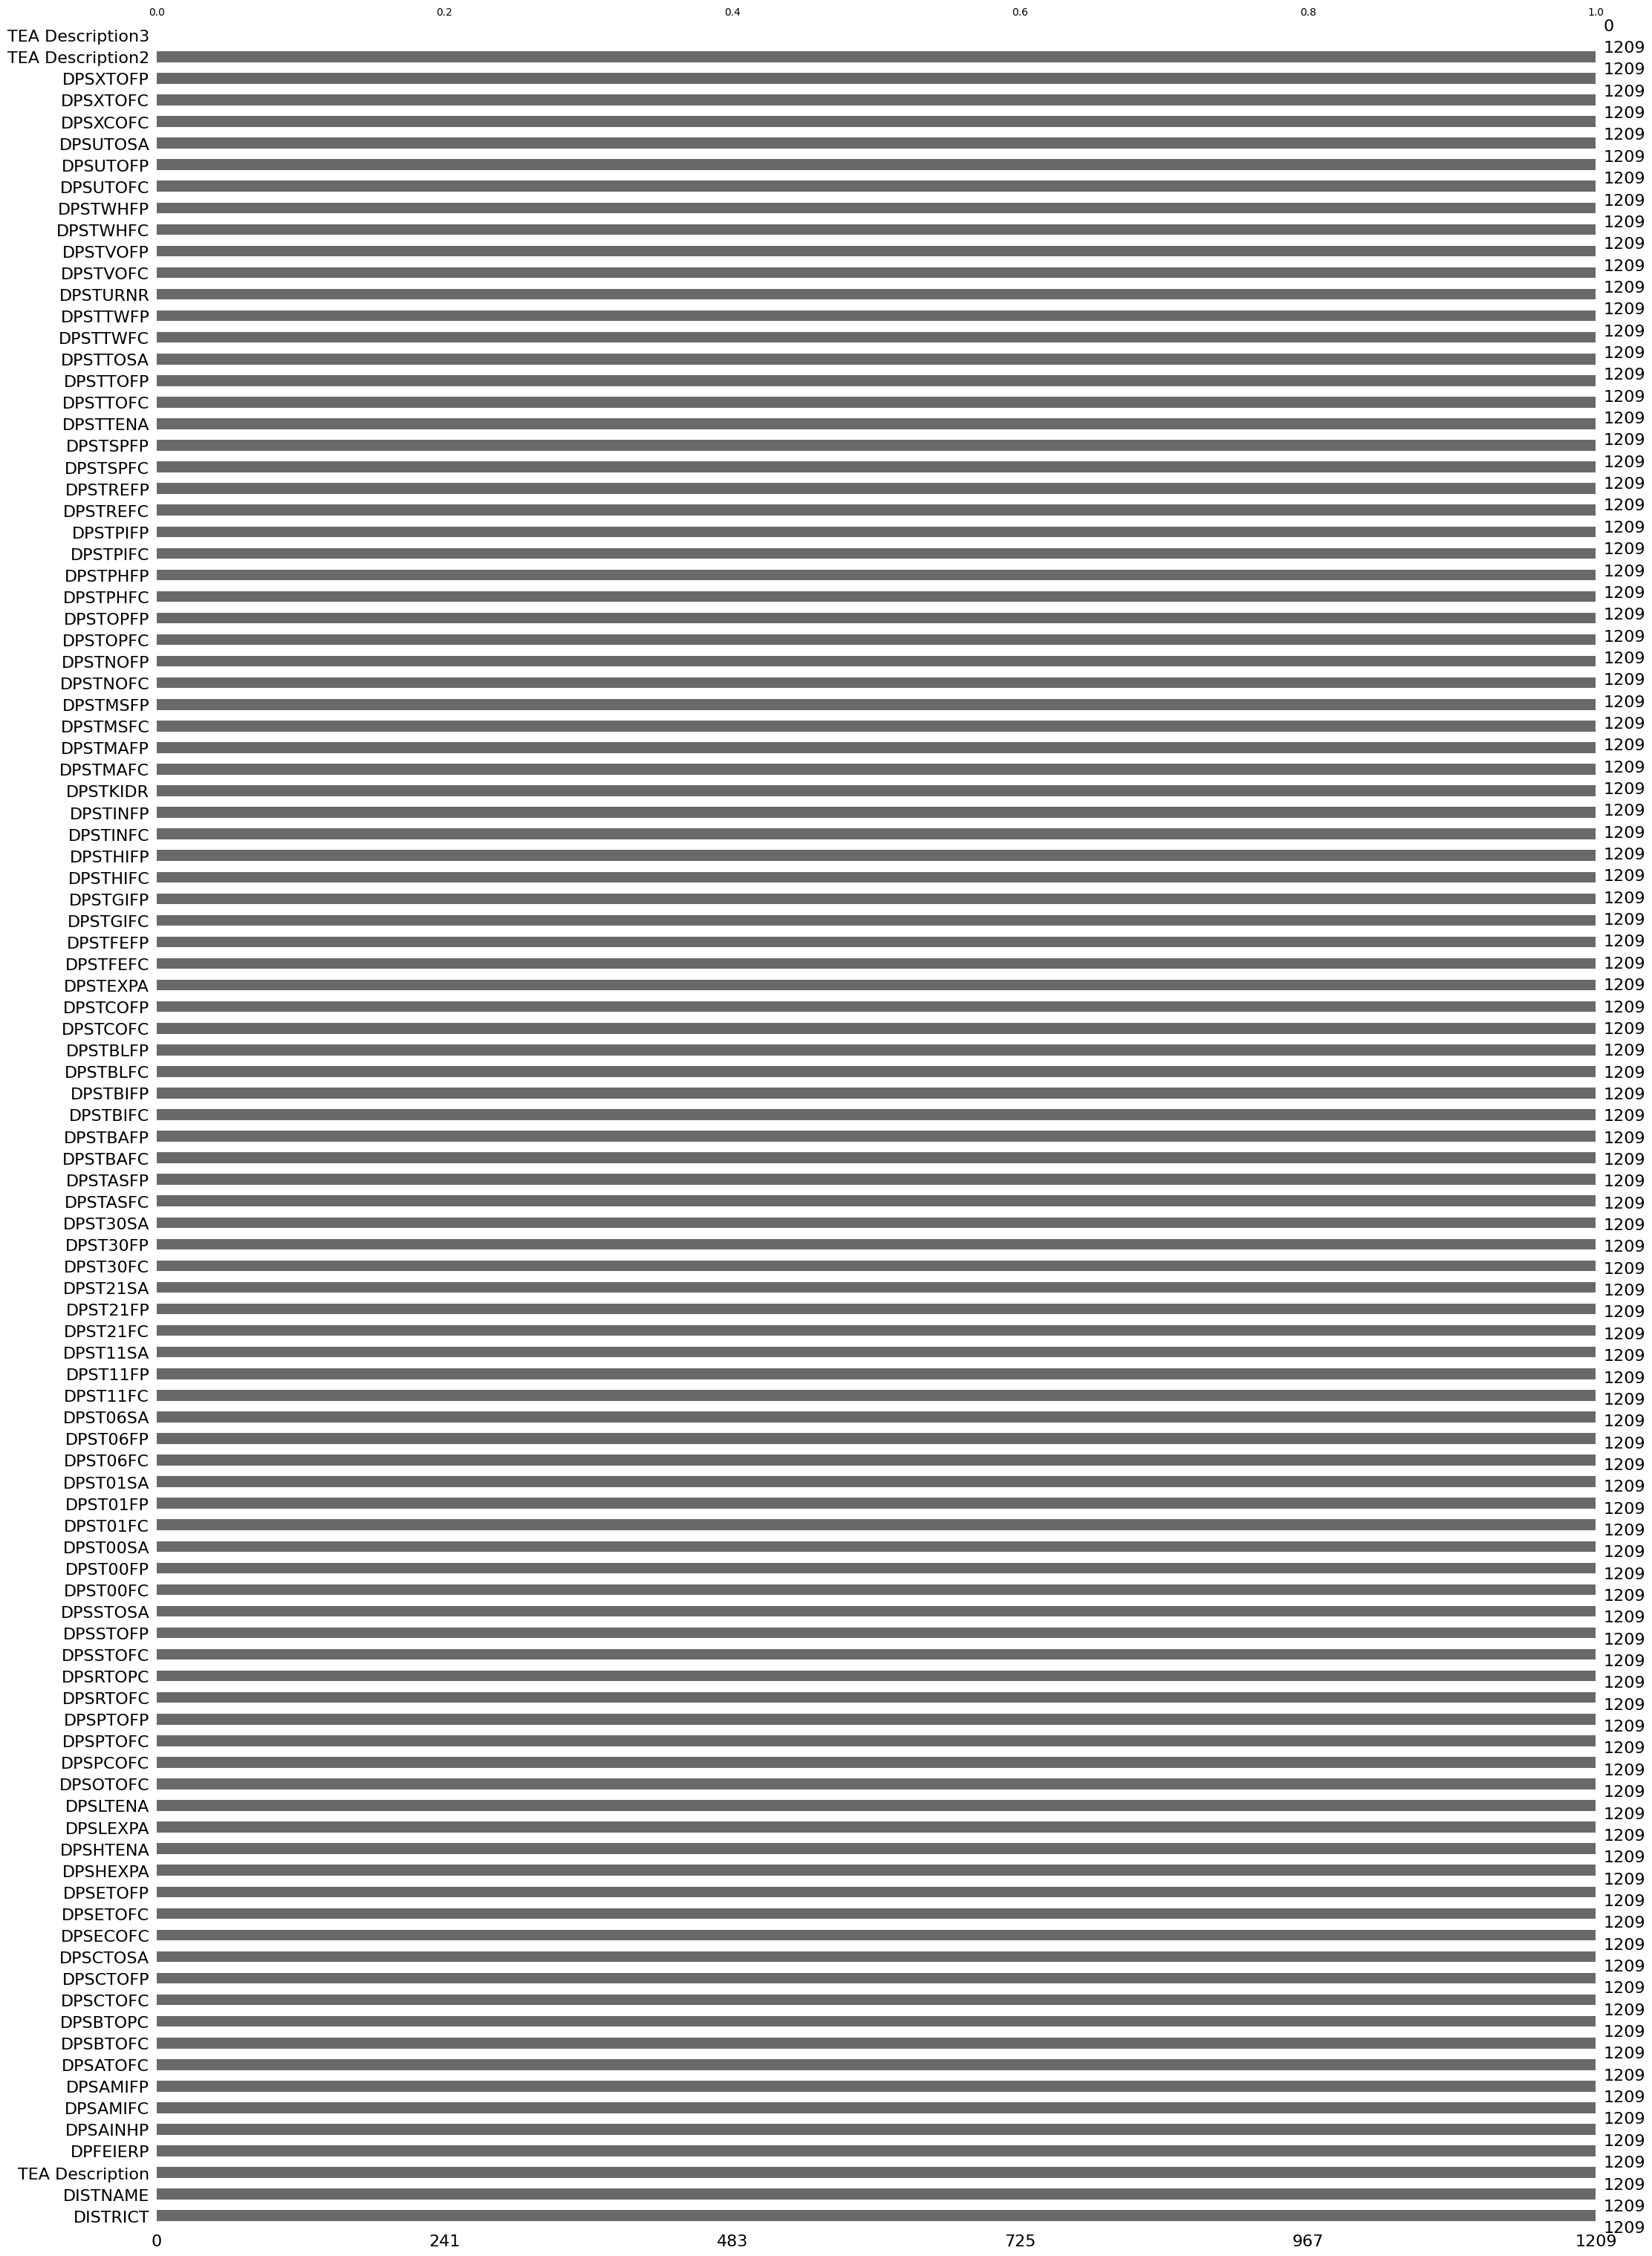

In [13]:
import missingno as msno
msno.bar(df_turnover)

In [15]:
import numpy as np

# Select only numeric columns
numeric_df = df_turnover.select_dtypes(include=np.number)

# Compute Z-scores
z_scores = (numeric_df - numeric_df.mean()) / numeric_df.std()

# Find outliers (threshold = 3)
outliers = (np.abs(z_scores) > 3)

# Count outliers per column
outlier_counts = outliers.sum()

print(outlier_counts.sort_values(ascending=False))

TEA Description3    0
dtype: int64


No outliers were found

In [16]:
# Show only columns with invalid values
numeric_df = df_turnover.select_dtypes(include=np.number)
# Count negative values in each column
invalid_negatives = (numeric_df < 0).sum()

# Show only columns with invalid values
print(invalid_negatives[invalid_negatives > 0])

Series([], dtype: int64)


In [18]:
# Find duplicate ISDs based on District Name
duplicates = df_turnover[df_turnover.duplicated(subset='DISTNAME', keep=False)]
#Verify is duplicates are removed
print("Duplicate ISDs:")
print(duplicates)
print("Number of duplicate rows:", df_turnover.duplicated(subset='DISTNAME').sum())
duplicate_names = df_turnover['DISTNAME'][df_turnover.duplicated(subset='DISTNAME')]
print(duplicate_names)
#identify duplicates
df_clean = df_turnover.drop_duplicates(subset='DISTNAME', keep=False)
#Remove all the duplicates
print("Remaining duplicates:", df_clean.duplicated(subset='DISTNAME').sum())

Duplicate ISDs:
     DISTRICT           DISTNAME              TEA Description DPFEIERP  \
81    '015905       EDGEWOOD ISD               Major Suburban     58.5   
91    '015915      NORTHSIDE ISD                  Major Urban     66.2   
116   '019913        HUBBARD ISD                        Rural     67.9   
192   '039905         MIDWAY ISD                        Rural     61.5   
212   '043914          WYLIE ISD  Other Central City Suburban     66.4   
231   '049903    VALLEY VIEW ISD      Non-metropolitan Stable     54.2   
290   '057911  HIGHLAND PARK ISD               Major Suburban     66.7   
297   '058902         DAWSON ISD                        Rural     45.1   
590   '108916    VALLEY VIEW ISD  Other Central City Suburban       60   
595   '109905        HUBBARD ISD                        Rural     53.1   
741   '145902    CENTERVILLE ISD                        Rural     61.6   
796   '161903         MIDWAY ISD  Other Central City Suburban     64.1   
866   '175904         

In [20]:
#Finding rare categories
rare_summary = {}

for col in df_turnover.select_dtypes(include='object').columns:
    freq = df_turnover[col].value_counts(normalize=True)
    rare = freq[freq < 0.05]

    if len(rare) > 0:
        rare_summary[col] = rare

# Print results
for col, values in rare_summary.items():
    print(f"\nColumn: {col}")
    print(values)


Column: DISTRICT
DISTRICT
'254902    0.000827
'001902    0.000827
'001903    0.000827
'001904    0.000827
'001906    0.000827
             ...   
'003906    0.000827
'003905    0.000827
'003904    0.000827
'003903    0.000827
'003902    0.000827
Name: proportion, Length: 1209, dtype: float64

Column: DISTNAME
DISTNAME
HUBBARD ISD                0.001654
EDGEWOOD ISD               0.001654
MIDWAY ISD                 0.001654
VALLEY VIEW ISD            0.001654
BIG SANDY ISD              0.001654
                             ...   
LAMAR CISD                 0.000827
CROWELL ISD                0.000827
LOCKNEY ISD                0.000827
FLOYDADA COLLEGIATE ISD    0.000827
TEAGUE ISD                 0.000827
Name: proportion, Length: 1198, dtype: float64

Column: TEA Description
TEA Description
Independent Town                 0.043838
Other Central City               0.028950
Non-metropolitan Fast Growing    0.028122
Major Urban                      0.009098
Name: proportion, dtype: fl